In [5]:

# PALMER PENGUINS — ANALISI E SPERIMENTAZIONE MEAN-SHIFT
# Componente 2 — Modelli e principi della percezione

# 1. IMPORTAZIONE LIBRERIE

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


# 2. CARICAMENTO DEI DATASET

# Percorsi possibili: repository GitHub oppure Colab
cartelle_possibili = [
    Path("data/processed"),
    Path("../data/processed"),
    Path(".")
]

cartella_dati = next(
    (
        p for p in cartelle_possibili
        if (p / "penguins_meanshift_X_std.csv").is_file()
        and (p / "penguins_metadata_eval.csv").is_file()
    ),
    None
)

if cartella_dati is None:
    raise FileNotFoundError(
        "Caricare entrambi i CSV in Colab oppure "
        "inserirli nella cartella data/processed del repository."
    )

# Individuiamo anche la cartella principale del progetto
if cartella_dati.name == "processed" and cartella_dati.parent.name == "data":
    ROOT = cartella_dati.parent.parent
else:
    ROOT = Path(".")

df = pd.read_csv(cartella_dati / "penguins_meanshift_X_std.csv")
metadata = pd.read_csv(cartella_dati / "penguins_metadata_eval.csv")

# Matrice numerica su cui lavorerà Mean-Shift
X = df.to_numpy(dtype=float)

print("Dimensioni dataset:", X.shape)
print("Valori mancanti:\n", df.isna().sum())


# 3. CONTROLLI SUI DATI PREPARATI

features = [
    "Culmen Length (mm)",
    "Culmen Depth (mm)",
    "Flipper Length (mm)",
    "Body Mass (g)"
]

assert list(df.columns) == features
assert X.shape == (342, 4)
assert np.isfinite(X).all()
assert len(metadata) == len(X)
assert metadata["Original_Row_Index"].is_unique

# Verifichiamo che gli Z-score coincidano con quelli
# ricalcolati dalle misure fisiche originali.
# Questo è un controllo: NON standardizziamo di nuovo X.
X_controllo = StandardScaler().fit_transform(metadata[features])

np.testing.assert_allclose(
    X,
    X_controllo,
    rtol=1e-8,
    atol=1e-8
)

print("\nControlli dei dati: SUPERATI")


# 4. PRIMA APPLICAZIONE DI MEAN-SHIFT

# Stima iniziale del bandwidth
h = estimate_bandwidth(X, quantile=0.2)

# MeanShift di scikit-learn utilizza un flat kernel.
# Manteniamo i parametri predefiniti già usati negli esperimenti.
modello_iniziale = MeanShift(bandwidth=h)
modello_iniziale.fit(X)

print("\n--- PRIMO CLUSTERING ---")
print("Bandwidth stimato:", h)
print("Numero di cluster:", len(np.unique(modello_iniziale.labels_)))

print("Pinguini per cluster:")
print(pd.Series(modello_iniziale.labels_).value_counts().sort_index())

print("Coordinate dei mode:")
print(modello_iniziale.cluster_centers_)


# 5. ANALISI DEL PINGUINO ISOLATO

indice_pinguino = 168

# Distanza euclidea in 4D da tutti i pinguini
differenze = X - X[indice_pinguino]
distanze = np.linalg.norm(differenze, axis=1)

# La prima distanza è 0: il punto confrontato con se stesso
distanze_ordinate = np.sort(distanze)
vicino_piu_prossimo = distanze_ordinate[1]

print("\n--- ANALISI PINGUINO 168 ---")
print("Indice nel dataset originale:",
      metadata.iloc[indice_pinguino]["Original_Row_Index"])
print("Cinque distanze più piccole:", distanze_ordinate[:5])
print("Distanza vicino più prossimo:", vicino_piu_prossimo)
print("Punti entro il bandwidth:", np.sum(distanze <= h))


# 6. ESPERIMENTI CON BANDWIDTH DIFFERENTI

# Sei valori iniziali + nove valori intermedi
bandwidth_iniziali = [1.0, 1.2, h, 1.5, 1.7, 2.0]

bandwidth_intermedi = [
    1.38, 1.40, 1.42, 1.44, 1.45,
    1.46, 1.47, 1.48, 1.49
]

bandwidths = sorted(set(bandwidth_iniziali + bandwidth_intermedi))

# Memorizziamo i risultati di ogni esecuzione
risultati = {}
righe_riepilogo = []

for bw in bandwidths:

    modello_test = MeanShift(bandwidth=bw)
    modello_test.fit(X)

    labels = modello_test.labels_
    etichette, conteggi = np.unique(labels, return_counts=True)
    n_cluster = len(etichette)

    # La silhouette è definita solo con almeno due cluster
    # e meno cluster del numero di osservazioni
    if 2 <= n_cluster < len(X):
        silhouette = silhouette_score(X, labels)
    else:
        silhouette = np.nan

    # Seguiamo il pinguino 168 attraverso gli esperimenti
    etichetta_168 = int(labels[indice_pinguino])
    dimensione_168 = int(np.sum(labels == etichetta_168))

    # Salviamo etichette e mode per riutilizzarli nei grafici
    risultati[bw] = {
        "labels": labels.copy(),
        "centri": modello_test.cluster_centers_.copy(),
        "silhouette": silhouette
    }

    righe_riepilogo.append({
        "bandwidth": bw,
        "n_cluster": n_cluster,
        "dimensioni": " / ".join(map(str, conteggi)),
        "silhouette": silhouette,
        "cluster_168": etichetta_168,
        "dimensione_cluster_168": dimensione_168
    })

# Tabella con tutti i risultati
riepilogo = pd.DataFrame(righe_riepilogo)

print("\n--- RIEPILOGO ESPERIMENTI ---")
print(riepilogo.round(4).to_string(index=False))


# 7. CONFRONTO TRA LE ASSEGNAZIONI

# Confrontiamo le due transizioni più interessanti:
# 4 -> 3 cluster e 3 -> 2 cluster

confronti = [
    (h, 1.40),
    (1.40, 1.46)
]

for bw_a, bw_b in confronti:

    tabella = pd.crosstab(
        risultati[bw_a]["labels"],
        risultati[bw_b]["labels"],
        rownames=[f"Cluster h={bw_a:.4f}"],
        colnames=[f"Cluster h={bw_b:.4f}"]
    )

    print(f"\n--- CONFRONTO h={bw_a:.4f} / h={bw_b:.4f} ---")
    print(tabella)

    assert tabella.to_numpy().sum() == len(X)


# 8. CONFIGURAZIONI PER LA VALIDAZIONE ESTERNA

# h=2.0: migliore silhouette tra i valori testati
# h=1.4: configurazione intermedia per analisi di sensibilità

labels_finali = risultati[2.0]["labels"]
labels_alternativi = risultati[1.40]["labels"]

risultati_finali = metadata[["Original_Row_Index"]].copy()

risultati_finali["cluster_h2_0"] = labels_finali
risultati_finali["cluster_h1_4"] = labels_alternativi

# Cartella di esportazione
cartella_risultati = ROOT / "results"
cartella_risultati.mkdir(parents=True, exist_ok=True)

# Salviamo assegnazioni e riepilogo degli esperimenti
risultati_finali.to_csv(
    cartella_risultati / "penguins_cluster_assignments.csv",
    index=False
)

riepilogo.to_csv(
    cartella_risultati / "riepilogo_bandwidth.csv",
    index=False
)

# Verifiche finali
assert risultati_finali.shape == (342, 3)
assert risultati_finali["Original_Row_Index"].is_unique
assert risultati_finali.notna().all().all()

print("\n--- ESPORTAZIONE COMPLETATA ---")
print("Dimensioni:", risultati_finali.shape)

print("\nCluster con h=2.0:")
print(risultati_finali["cluster_h2_0"].value_counts().sort_index())

print("\nCluster con h=1.4:")
print(risultati_finali["cluster_h1_4"].value_counts().sort_index())

print("\nFile salvati in:", cartella_risultati)


Dimensioni dataset: (342, 4)
Valori mancanti:
 Culmen Length (mm)     0
Culmen Depth (mm)      0
Flipper Length (mm)    0
Body Mass (g)          0
dtype: int64

Controlli dei dati: SUPERATI

--- PRIMO CLUSTERING ---
Bandwidth stimato: 1.3705084838298949
Numero di cluster: 4
Pinguini per cluster:
0    132
1    123
2     86
3      1
Name: count, dtype: int64
Coordinate dei mode:
[[-0.97166474  0.47527798 -0.85852994 -0.7565414 ]
 [ 0.53967135 -1.23645456  1.03088458  0.94875552]
 [ 0.52957786  0.67817298 -0.3546227  -0.49449855]
 [ 2.5823759   0.32903754 -1.41834665 -0.6265811 ]]

--- ANALISI PINGUINO 168 ---
Indice nel dataset originale: 169
Cinque distanze più piccole: [0.         1.45887147 1.62902101 1.65794814 1.66883851]
Distanza vicino più prossimo: 1.4588714733938402
Punti entro il bandwidth: 1

--- RIEPILOGO ESPERIMENTI ---
 bandwidth  n_cluster         dimensioni  silhouette  cluster_168  dimensione_cluster_168
    1.0000          4 137 / 123 / 81 / 1      0.4296            3  

Dimensioni PCA: (342, 2)
Varianza spiegata: [0.68843878 0.19312919]
Varianza totale: 0.8815679694372628


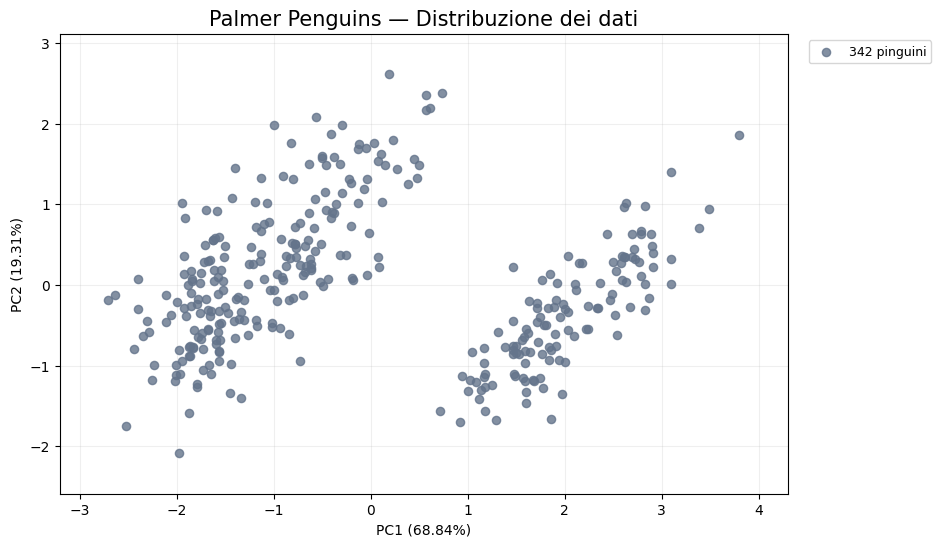

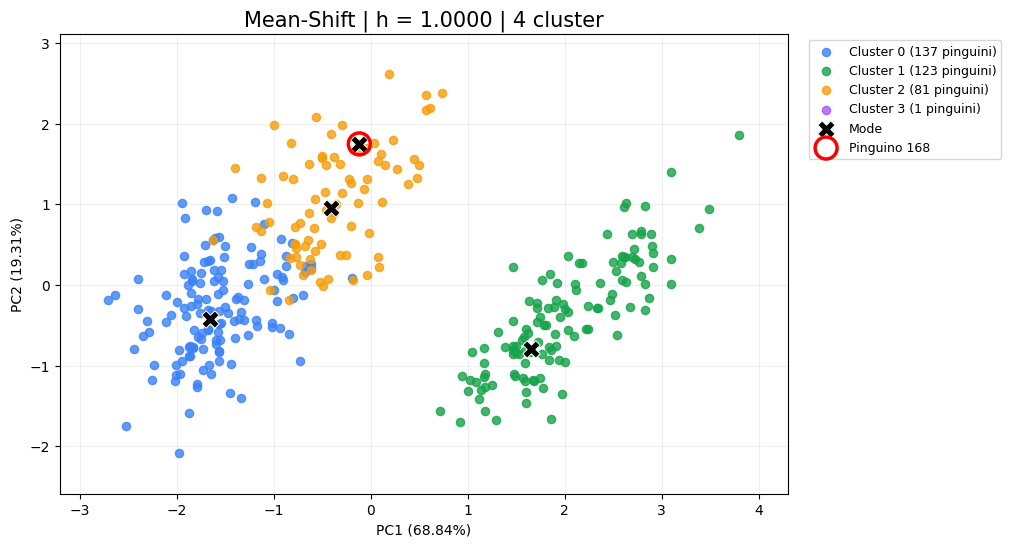

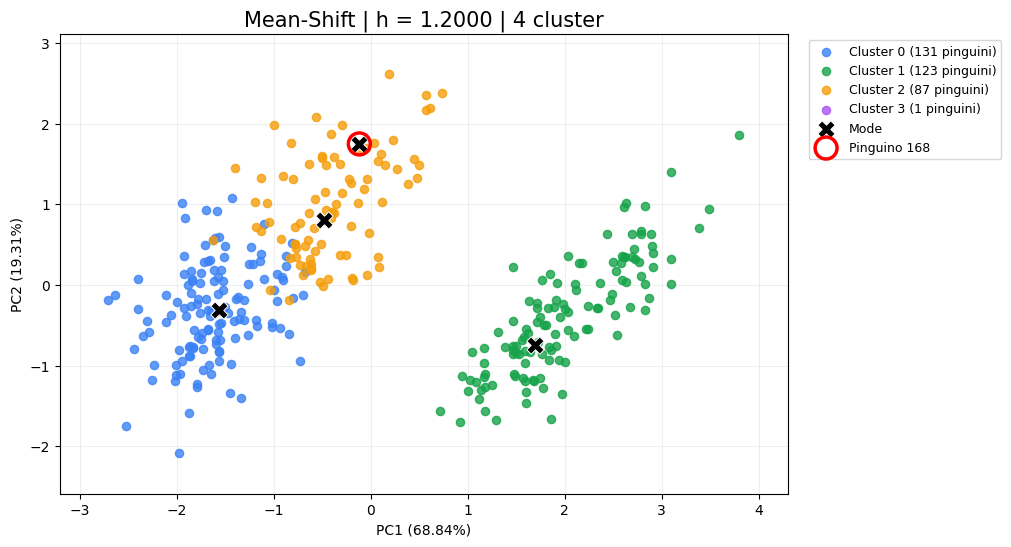

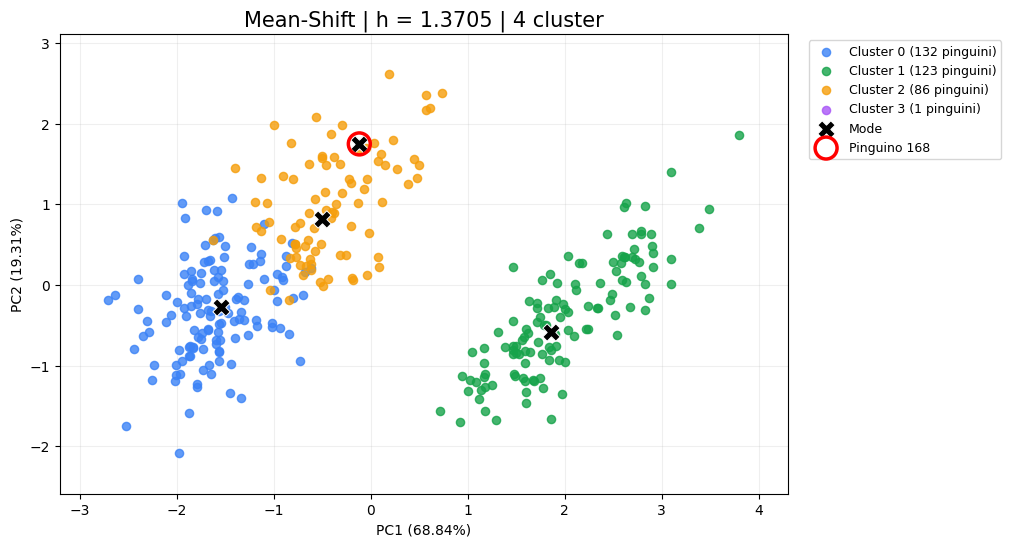

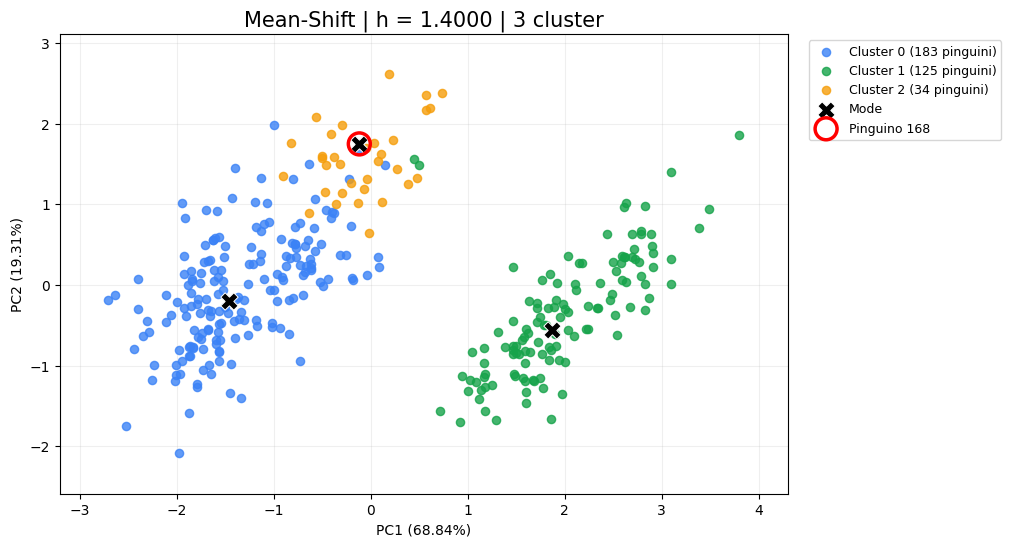

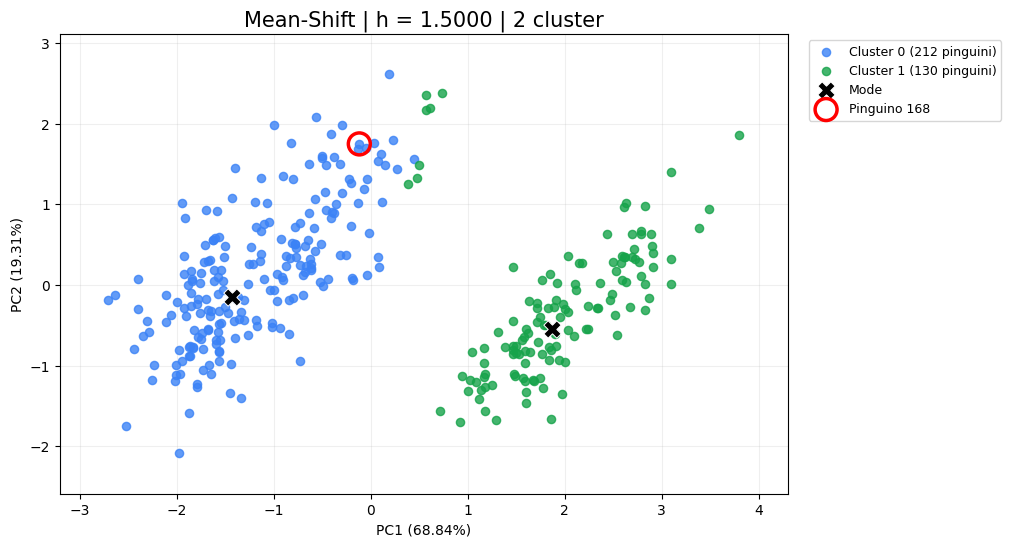

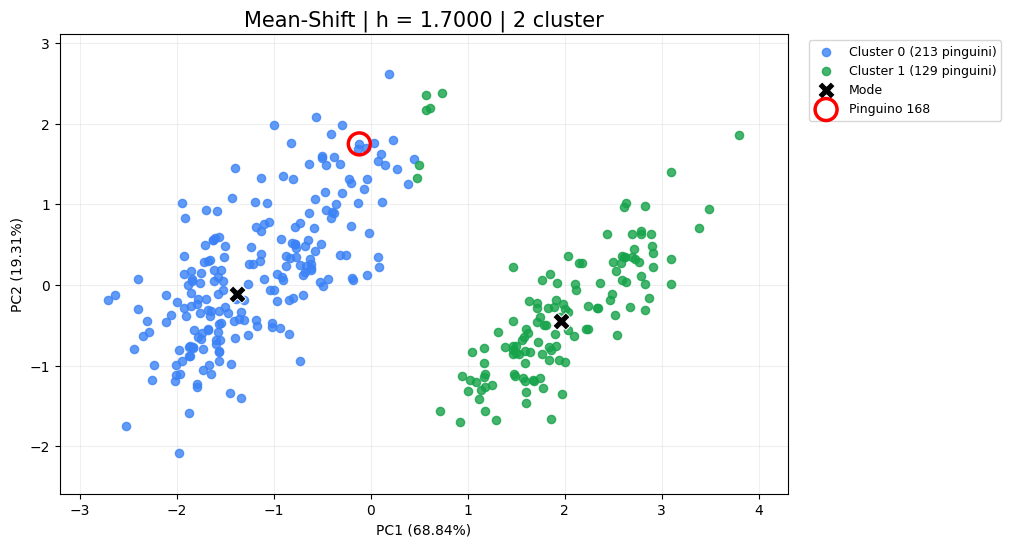

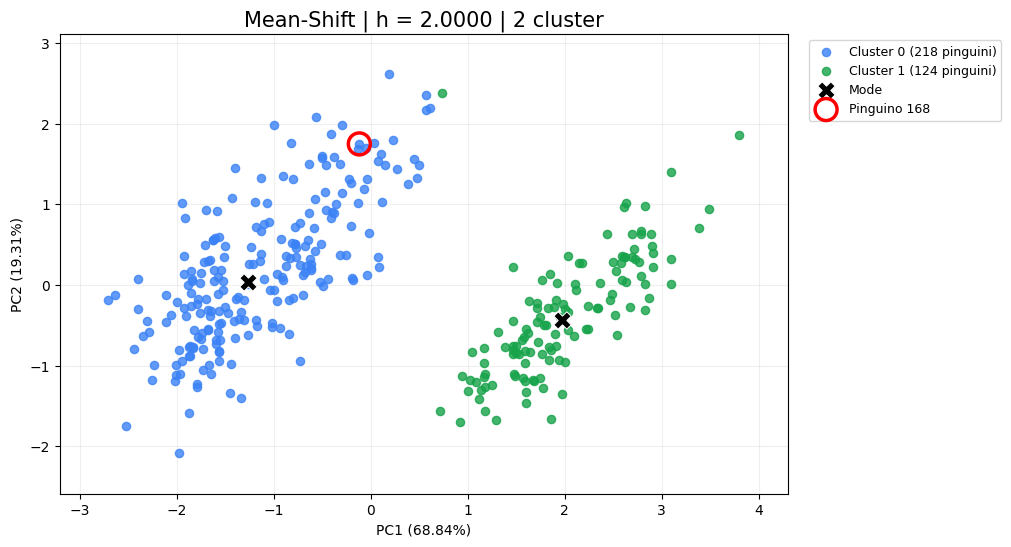

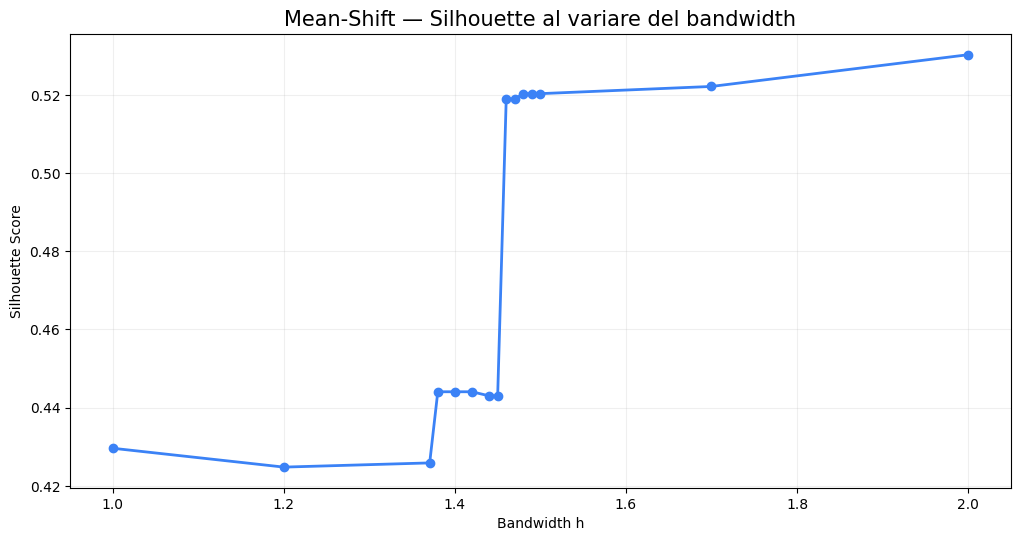


Grafici salvati in: figures/meanshift
Archivio ZIP: /content/grafici_meanshift.zip


In [6]:

# PALMER PENGUINS — VISUALIZZAZIONE DEI RISULTATI

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from pathlib import Path
import shutil


# 1. RIDUZIONE DIMENSIONALE SOLO PER LA VISUALIZZAZIONE

# Mean-Shift ha già lavorato sui dati standardizzati in 4D.
# La PCA serve esclusivamente a mostrare i risultati in 2D.

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print("Dimensioni PCA:", X_pca.shape)
print("Varianza spiegata:", pca.explained_variance_ratio_)
print("Varianza totale:",
      pca.explained_variance_ratio_.sum())


# 2. PREPARAZIONE DELLA CARTELLA

cartella_grafici = ROOT / "figures" / "meanshift"
cartella_grafici.mkdir(parents=True, exist_ok=True)

# Valori scelti per la sequenza della presentazione:
# i sei originali + h=1.40 (passaggio intermedio a 3 cluster)
bandwidth_grafici = [1.0, 1.2, h, 1.40, 1.5, 1.7, 2.0]

# Colori associati alle etichette numeriche dei cluster.
# Le etichette non rappresentano necessariamente gli stessi
# gruppi tra esperimenti differenti.
colori = {
    0: "#3B82F6",
    1: "#16A34A",
    2: "#F59E0B",
    3: "#A855F7"
}

# Limiti identici per tutti i grafici
lim_x = (X_pca[:, 0].min() - 0.5, X_pca[:, 0].max() + 0.5)
lim_y = (X_pca[:, 1].min() - 0.5, X_pca[:, 1].max() + 0.5)


# 3. FUNZIONI PER MANTENERE LO STESSO STILE

def prepara_grafico(titolo):

    # Dimensioni panoramiche adatte alle slide
    fig, ax = plt.subplots(figsize=(11.2, 6.3))

    # Margini fissi: stessa dimensione per ogni immagine
    fig.subplots_adjust(
        left=0.08,
        right=0.73,
        bottom=0.14,
        top=0.87
    )

    ax.set_title(titolo, fontsize=15)

    ax.set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
    )

    ax.set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
    )

    ax.set_xlim(lim_x)
    ax.set_ylim(lim_y)
    ax.set_axisbelow(True)
    ax.grid(alpha=0.2)

    return fig, ax


def salva_grafico(fig, nome):

    # PNG ad alta risoluzione
    fig.savefig(
        cartella_grafici / f"{nome}.png",
        dpi=300,
        facecolor="white"
    )

    # SVG vettoriale
    fig.savefig(
        cartella_grafici / f"{nome}.svg",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)


# 4. GRAFICO DELLA DISTRIBUZIONE SENZA CLUSTER

fig, ax = prepara_grafico(
    "Palmer Penguins — Distribuzione dei dati"
)

ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    color="#64748B",
    s=35,
    alpha=0.8,
    label="342 pinguini"
)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

salva_grafico(fig, "00_distribuzione_pca")


# 5. SETTE GRAFICI CON BANDWIDTH DIFFERENTI

for bw in bandwidth_grafici:

    # Recuperiamo il risultato già calcolato nella cella 1
    labels = risultati[bw]["labels"]
    centri = risultati[bw]["centri"]

    n_cluster = len(np.unique(labels))

    # Proiettiamo i mode usando la STESSA PCA dei punti
    mode_pca = pca.transform(centri)

    fig, ax = prepara_grafico(
        f"Mean-Shift | h = {bw:.4f} | {n_cluster} cluster"
    )

    # Ogni colore corrisponde a un'etichetta di cluster
    for k in np.unique(labels):

        selezione = labels == k

        ax.scatter(
            X_pca[selezione, 0],
            X_pca[selezione, 1],
            color=colori[int(k)],
            s=35,
            alpha=0.8,
            label=f"Cluster {k} ({np.sum(selezione)} pinguini)"
        )

    # Evidenziamo i mode con una X nera
    ax.scatter(
        mode_pca[:, 0],
        mode_pca[:, 1],
        color="black",
        marker="X",
        s=155,
        edgecolors="white",
        linewidths=0.7,
        label="Mode",
        zorder=5
    )

    # Pinguino 168: cerchio rosso senza riempimento
    ax.scatter(
        X_pca[168, 0],
        X_pca[168, 1],
        facecolors="none",
        edgecolors="red",
        linewidths=2.5,
        s=250,
        label="Pinguino 168",
        zorder=6
    )

    # Legenda nella stessa posizione in tutti i grafici
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        fontsize=9
    )

    # Nome univoco del file
    nome_h = f"{bw:.4f}".replace(".", "_")
    nome_file = f"meanshift_h_{nome_h}"

    salva_grafico(fig, nome_file)


# 6. GRAFICO RIASSUNTIVO DELLA SILHOUETTE

fig, ax = plt.subplots(figsize=(11.2, 6.3))

fig.subplots_adjust(
    left=0.10,
    right=0.94,
    bottom=0.15,
    top=0.87
)

ax.plot(
    riepilogo["bandwidth"],
    riepilogo["silhouette"],
    marker="o",
    linewidth=2,
    color="#3B82F6"
)

ax.set_title(
    "Mean-Shift — Silhouette al variare del bandwidth",
    fontsize=15
)

ax.set_xlabel("Bandwidth h")
ax.set_ylabel("Silhouette Score")
ax.grid(alpha=0.2)

salva_grafico(fig, "silhouette_vs_bandwidth")


# 7. CREAZIONE ARCHIVIO ZIP

# Lo ZIP contiene PNG e SVG senza perdita di qualità.
percorso_zip = shutil.make_archive(
    str(ROOT / "grafici_meanshift"),
    "zip",
    root_dir=cartella_grafici
)


# GRAFICO — Numero di cluster al variare del bandwidth

fig, ax = plt.subplots(figsize=(11.2, 6.3))

fig.subplots_adjust(
    left=0.10, right=0.94, bottom=0.16, top=0.85
)

ax.plot(
    riepilogo["bandwidth"],
    riepilogo["n_cluster"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Mean-Shift — Numero di cluster al variare del bandwidth",
    fontsize=15
)

ax.set_xlabel("Bandwidth h")
ax.set_ylabel("Numero di cluster")
ax.set_yticks([2, 3, 4])
ax.set_ylim(1.7, 4.3)
ax.set_xlim(0.97, 2.03)
ax.grid(alpha=0.2)

fig.text(
    0.52, 0.035,
    "Transizioni osservate tra 1,3705–1,38 e tra 1,45–1,46",
    ha="center",
    fontsize=10
)

salva_grafico(fig, "numero_cluster_vs_bandwidth")


print("\nGrafici salvati in:", cartella_grafici)
print("Archivio ZIP:", percorso_zip)
